In [72]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import sys

# -----------------------------
# 配置参数
# -----------------------------
SERIAL_PORT = "COM31"  # Linux 示例，Windows 可改为 "COM3"
BAUDRATE = 5000000               # 默认波特率
DATA_TO_SEND = 0x88           # 要发送的字节

# -----------------------------
# 发送函数
# -----------------------------
def send_byte(port, baudrate, byte_val):
    try:
        # 打开串口
        with serial.Serial(port, baudrate, timeout=1) as ser:
            # 发送单个字节
            ser.write(bytes([byte_val]))
            print(f"Sent byte 0x{byte_val:02X} to {port} at {baudrate} baud.")
    except serial.SerialException as e:
        print(f"Error opening/writing serial port: {e}")
        sys.exit(1)


send_byte(SERIAL_PORT, BAUDRATE, DATA_TO_SEND)


Sent byte 0x88 to COM31 at 5000000 baud.


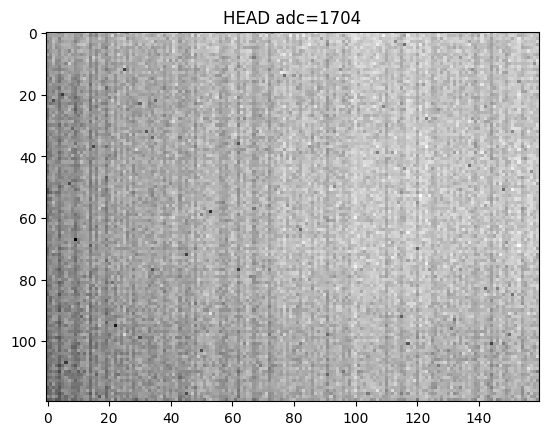

Stopped by user
Saved 23 groups to capture_20260129_113142\frames.npy
11.901092052459717


In [150]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime


class ImagePacketDecoder:
    """
    RAW16 UART 图像包解析器（支持行扩展 + ADC）

    UART 包格式:
        FF FF +
        H * (W + 2) * u16   (图像 + 行扩展, BE) +
        1 * u16            (ADC, BE)

    输出:
        img_all : (H, W + 2) u16
        adc     : u16
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height

        self.line_words = self.width + 2
        self.total_words = self.height * self.line_words + 1
        self.packet_size = 2 + self.total_words * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)
        if calib.shape != (self.height, self.width):
            raise ValueError("Calibration shape mismatch")
        self.calib = calib.astype(np.int32)

    @staticmethod
    def gray_to_binary(img):
        # 直通，保留接口
        return img

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        buf8 = np.frombuffer(packet[2:], dtype=np.uint8)

        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        adc_raw = raw16[-1]
        raw16_main = raw16[:-1]

        raw16_all = raw16_main.reshape(
            (self.height, self.line_words)
        )

        raw_img = raw16_all[:, :self.width]
        raw_ext = raw16_all[:, self.width:]

        img_bin = self.gray_to_binary(raw_img).astype(np.int32)
        if self.calib is not None:
            img_bin -= self.calib
            img_bin = np.clip(img_bin, 0, 65535)

        img_all = np.concatenate(
            [img_bin.astype(np.uint16), raw_ext.astype(np.uint16)],
            axis=1
        )

        return img_all, np.uint16(adc_raw)

def run_uart_capture(port, baud, width, height, calib_file=None):

    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder, exist_ok=True)

    npy_path = os.path.join(folder, "frames.npy")

    frame_dtype = np.dtype([
        ("img", np.uint16, (height, width + 2)),
        ("adc", np.uint16),
    ])

    frames = []

    decoder = ImagePacketDecoder(width, height, calib_file)
    buf = bytearray()

    # adc!=0 作为组首帧
    head_frame = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames (adc!=0 as head, Ctrl+C to stop)")

            while True:
                buf.extend(ser.read(4096))

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_all, adc = result

                    # ===== 组首帧：adc != 0 =====
                    if adc != 0:
                        head_frame = np.zeros((), dtype=frame_dtype)
                        head_frame["img"] = img_all
                        head_frame["adc"] = adc

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")
                        plt.title(f"HEAD adc={int(adc)}")
                        plt.show()
                        continue

                    # ===== 组尾帧：adc == 0 =====
                    if adc == 0 and head_frame is not None:
                        tail_frame = np.zeros((), dtype=frame_dtype)
                        tail_frame["img"] = img_all
                        tail_frame["adc"] = adc

                        frames.append(head_frame)
                        frames.append(tail_frame)

                        print(
                            f"Saved group #{len(frames)//2}, "
                            f"total frames={len(frames)}"
                        )

                        head_frame = None

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")
                        plt.title("TAIL adc=0")
                        plt.show()

    except KeyboardInterrupt:
        print("Stopped by user")

    frames_np = np.array(frames, dtype=frame_dtype)
    np.save(npy_path, frames_np)
    print(f"Saved {len(frames)//2} groups to {npy_path}")

import time
ltime = time.time()
run_uart_capture(
    port="COM31",
    baud=5_000_000,
    width=160,
    height=120,
    calib_file=None,
)
print(time.time()- ltime)


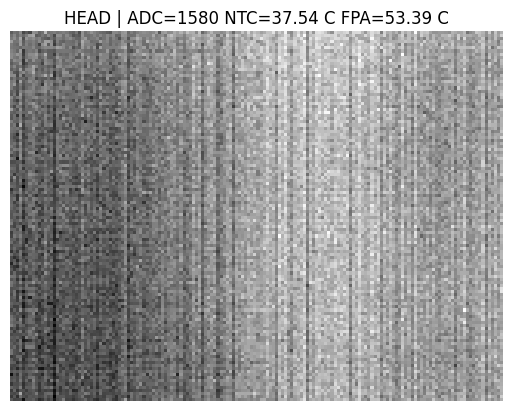

Stopped by user
Saved 35 groups to capture_20260129_135517\frames.npy
21.391101598739624


In [156]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime

# =============================
# ADC / VTEMP 温度计算
# =============================

RUP = 10_000.0
R0  = 10_000.0
T0  = 298.15
B   = 3435.0

def adc_to_rntc(adc):
    adc = float(adc)
    if adc <= 0 or adc >= 4095:
        return np.nan
    return RUP * adc / (4095.0 - adc)

def rntc_to_temp_c(r):
    if r <= 0 or np.isnan(r):
        return np.nan
    inv_T = 1.0 / T0 + np.log(r / R0) / B
    return 1.0 / inv_T - 273.15

def adc_to_temp_c(adc):
    return rntc_to_temp_c(adc_to_rntc(adc))

def vtemp_to_fpa_temp_c(vtemp_mean):
    return 25.0 + (vtemp_mean - 8192.0) / 70.0

class ImagePacketDecoder:
    """
    RAW16 UART 图像包解析器（支持行扩展 + ADC）

    UART 包格式:
        FF FF +
        H * (W + 2) * u16   (图像 + 行扩展, BE) +
        1 * u16            (ADC, BE)

    输出:
        img_all : (H, W + 2) u16
        adc     : u16
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height

        self.line_words = self.width + 2
        self.total_words = self.height * self.line_words + 1
        self.packet_size = 2 + self.total_words * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)
        if calib.shape != (self.height, self.width):
            raise ValueError("Calibration shape mismatch")
        self.calib = calib.astype(np.int32)

    @staticmethod
    def gray_to_binary(img):
        # 直通，保留接口
        return img

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        buf8 = np.frombuffer(packet[2:], dtype=np.uint8)

        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        adc_raw = raw16[-1]
        raw16_main = raw16[:-1]

        raw16_all = raw16_main.reshape(
            (self.height, self.line_words)
        )

        raw_img = raw16_all[:, :self.width]
        raw_ext = raw16_all[:, self.width:]

        img_bin = self.gray_to_binary(raw_img).astype(np.int32)
        if self.calib is not None:
            img_bin -= self.calib
            img_bin = np.clip(img_bin, 0, 65535)

        img_all = np.concatenate(
            [img_bin.astype(np.uint16), raw_ext.astype(np.uint16)],
            axis=1
        )

        return img_all, np.uint16(adc_raw)

def run_uart_capture(port, baud, width, height, calib_file=None):

    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder, exist_ok=True)

    npy_path = os.path.join(folder, "frames.npy")

    frame_dtype = np.dtype([
        ("img", np.uint16, (height, width + 2)),
        ("adc", np.uint16),
    ])

    frames = []

    decoder = ImagePacketDecoder(width, height, calib_file)
    buf = bytearray()

    # adc!=0 作为组首帧
    head_frame = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames (adc!=0 as head, Ctrl+C to stop)")

            while True:
                buf.extend(ser.read(4096))

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_all, adc = result

                    # ===== 组首帧：adc != 0 =====
                    if adc != 0:
                        head_frame = np.zeros((), dtype=frame_dtype)
                        head_frame["img"] = img_all
                        head_frame["adc"] = adc

                        clear_output(wait=True)
                        # plt.imshow(img_all[:, :width], cmap="gray")
                        # plt.title(f"HEAD adc={int(adc)}")
                        # plt.show()
                        # ===== VTEMP 当前帧平均 =====
                        vtemp = img_all[:, width:width+2].astype(np.float64)
                        vtemp_mean = np.mean(vtemp)
                        temp_fpa_c = vtemp_to_fpa_temp_c(vtemp_mean)

                        # ===== ADC 温度 =====
                        temp_adc_c = adc_to_temp_c(adc)

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")

                        title = (
                            f"HEAD | ADC={int(adc)} "
                            f"NTC={temp_adc_c:.2f} C "
                            f"FPA={temp_fpa_c:.2f} C"
                        )
                        plt.title(title)

                        plt.axis("off")
                        plt.show()
                        continue

                    # ===== 组尾帧：adc == 0 =====
                    if adc == 0 and head_frame is not None:
                        tail_frame = np.zeros((), dtype=frame_dtype)
                        tail_frame["img"] = img_all
                        tail_frame["adc"] = adc

                        frames.append(head_frame)
                        frames.append(tail_frame)

                        print(
                            f"Saved group #{len(frames)//2}, "
                            f"total frames={len(frames)}"
                        )

                        head_frame = None

                        clear_output(wait=True)
                        # plt.imshow(img_all[:, :width], cmap="gray")
                        # plt.title("TAIL adc=0")
                        # plt.show()
                        vtemp = img_all[:, width:width+2].astype(np.float64)
                        vtemp_mean = np.mean(vtemp)
                        temp_fpa_c = vtemp_to_fpa_temp_c(vtemp_mean)

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")

                        title = (
                            f"TAIL | ADC=0 "
                            f"FPA={temp_fpa_c:.2f} C"
                        )
                        plt.title(title)

                        plt.axis("off")
                        plt.show()

    except KeyboardInterrupt:
        print("Stopped by user")

    frames_np = np.array(frames, dtype=frame_dtype)
    np.save(npy_path, frames_np)
    print(f"Saved {len(frames)//2} groups to {npy_path}")

import time
ltime = time.time()
run_uart_capture(
    port="COM31",
    baud=5_000_000,
    width=160,
    height=120,
    calib_file=None,
)
print(time.time()- ltime)


In [117]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# NTC 参数（固定）
# -----------------------------
RUP = 10_000.0      # 上拉电阻 10kΩ
R0  = 10_000.0      # 25℃ 标称电阻
T0  = 298.15        # 25℃ = 298.15K
B   = 3435.0        # B 值

def adc_to_rntc(adc):
    """
    ADC -> NTC 电阻（Ohm）
    """
    adc = float(adc)
    if adc <= 0 or adc >= 4095:
        return np.nan
    return RUP * adc / (4095.0 - adc)

def rntc_to_temp_c(r):
    """
    NTC 电阻 -> 温度（℃）
    """
    if r <= 0 or np.isnan(r):
        return np.nan
    inv_T = 1.0 / T0 + np.log(r / R0) / B
    return 1.0 / inv_T - 273.15

def adc_to_temp_c(adc):
    """
    ADC -> 温度（℃）
    """
    r = adc_to_rntc(adc)
    return rntc_to_temp_c(r)

def show_frame_group(npy_file, group_idx, width):
    """
    显示 frames.npy 中指定 index 的一组图像，并解码 ADC → 温度
    """

    frames = np.load(npy_file)

    if frames.dtype.fields is None:
        raise ValueError("frames.npy is not a structured array")

    total_groups = len(frames) // 2
    if group_idx < 0 or group_idx >= total_groups:
        raise IndexError(
            f"group_idx out of range (0 ~ {total_groups - 1})"
        )

    head = frames[group_idx * 2]
    tail = frames[group_idx * 2 + 1]

    img_head = head["img"][:, :width]
    img_tail = tail["img"][:, :width]

    # ===== ADC 解码 =====
    adc_head = int(head["adc"])
    adc_tail = int(tail["adc"])

    temp_head = adc_to_temp_c(adc_head)
    temp_tail = adc_to_temp_c(adc_tail)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(img_head, cmap="gray")
    axes[0].set_title(
        f"HEAD  adc={adc_head}  T={temp_head:.2f}℃"
        if not np.isnan(temp_head)
        else f"HEAD  adc={adc_head}"
    )

    axes[1].imshow(img_tail, cmap="gray")
    axes[1].set_title(
        f"TAIL  adc={adc_tail}  T={temp_tail:.2f}℃"
        if not np.isnan(temp_tail)
        else f"TAIL  adc={adc_tail}"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Group {group_idx} / {total_groups - 1}"
    )

    plt.tight_layout()
    plt.show()

show_frame_group(
    npy_file=r"capture_20260128_183517\frames.npy",
    group_idx=600,
    width=160
)

IndexError: group_idx out of range (0 ~ 21)

In [151]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import numpy as np


def split_frames(npy_file, out_dir, height=120, width=162):
    frames = np.load(npy_file)

    if frames.dtype.fields is None:
        raise ValueError("Input npy is not a structured array")

    if "img" not in frames.dtype.fields or "adc" not in frames.dtype.fields:
        raise ValueError("frames must contain 'img' and 'adc' fields")

    os.makedirs(out_dir, exist_ok=True)

    black_imgs = []
    shutter_imgs = []
    adc_list = []

    for frame in frames:
        img = frame["img"][:height, :width]
        adc = int(frame["adc"])

        if adc == 0:
            black_imgs.append(img)
        else:
            shutter_imgs.append(img)
            adc_list.append(adc)   # 只记录有效 ADC

    black_imgs = np.asarray(black_imgs)
    shutter_imgs = np.asarray(shutter_imgs)
    adc_arr = np.asarray(adc_list, dtype=np.int32)

    np.save(os.path.join(out_dir, "black_img.npy"), black_imgs)
    np.save(os.path.join(out_dir, "shutter_img.npy"), shutter_imgs)
    np.save(os.path.join(out_dir, "adc.npy"), adc_arr)

    print("Split finished:")
    print(f"  black frames   : {black_imgs.shape}")
    print(f"  shutter frames : {shutter_imgs.shape}")
    print(f"  adc array      : {adc_arr.shape}")


npy_file = r"capture_20260129_113142\frames.npy"
out_dir = r"capture_20260129_113142"

split_frames(npy_file, out_dir)


Split finished:
  black frames   : (23, 120, 162)
  shutter frames : (23, 120, 162)
  adc array      : (23,)


In [158]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import sys
import os
import numpy as np


def extract_ext(npy_file, img_width=160, ext_width=2, print_rows=10):
    imgs = np.load(npy_file)

    if imgs.ndim != 3:
        raise ValueError("Input array must be 3D: (N, H, W)")

    n, h, w = imgs.shape

    if w != img_width + ext_width:
        raise ValueError(
            f"Unexpected width: {w}, expect {img_width + ext_width}"
        )

    main_img = imgs[:, :, :img_width]
    ext = imgs[:, :, img_width:img_width + ext_width]

    print(f"Input file : {npy_file}")
    print(f"Image shape: {imgs.shape}")
    print(f"Ext shape  : {ext.shape}")

    # 打印每一帧的 ext（只打印前 print_rows 行）
    for i in range(n):
        print(f"\n[FRAME {i}] ext (first {print_rows} rows):")
        print(ext[i, :print_rows, :])

    out_dir = os.path.dirname(npy_file)
    base = os.path.splitext(os.path.basename(npy_file))[0]
    out_ext = os.path.join(out_dir, f"{base}_ext.npy")

    np.save(out_ext, ext)
    print(f"\nExt saved to: {out_ext}")

    return main_img, ext

extract_ext(r"260129_0000_hand_gndvcc_old_board_u16/black_img.npy")


Input file : 260129_0000_hand_gndvcc_old_board_u16/black_img.npy
Image shape: (23, 120, 162)
Ext shape  : (23, 120, 2)

[FRAME 0] ext (first 10 rows):
[[9283 9358]
 [9285 9359]
 [9294 9370]
 [9291 9367]
 [9283 9358]
 [9291 9364]
 [9291 9366]
 [9290 9365]
 [9294 9368]
 [9281 9357]]

[FRAME 1] ext (first 10 rows):
[[9283 9356]
 [9286 9362]
 [9287 9363]
 [9289 9363]
 [9289 9363]
 [9279 9352]
 [9289 9362]
 [9283 9359]
 [9286 9359]
 [9281 9356]]

[FRAME 2] ext (first 10 rows):
[[9298 9371]
 [9287 9360]
 [9304 9379]
 [9296 9371]
 [9292 9366]
 [9291 9364]
 [9300 9374]
 [9294 9368]
 [9295 9370]
 [9297 9372]]

[FRAME 3] ext (first 10 rows):
[[9315 9390]
 [9312 9384]
 [9313 9387]
 [9312 9385]
 [9296 9372]
 [9311 9385]
 [9305 9377]
 [9313 9384]
 [9309 9383]
 [9298 9373]]

[FRAME 4] ext (first 10 rows):
[[9313 9387]
 [9314 9385]
 [9311 9384]
 [9313 9387]
 [9310 9382]
 [9308 9381]
 [9315 9391]
 [9320 9394]
 [9316 9393]
 [9319 9396]]

[FRAME 5] ext (first 10 rows):
[[9322 9398]
 [9323 9396]
 [9321 9

(array([[[4012, 4522, 4729, ..., 4797, 4882, 4675],
         [4079, 4245, 4265, ..., 5377, 4879, 5009],
         [4084, 3977, 4646, ..., 5084, 4993, 4706],
         ...,
         [2811, 3087, 3503, ..., 4976, 4162, 4292],
         [3952, 3428, 4175, ..., 4144, 4072, 4578],
         [2695, 2884, 3277, ..., 4834, 4569, 3835]],
 
        [[3753, 4262, 4457, ..., 4860, 4946, 4731],
         [3881, 4039, 4062, ..., 5434, 4929, 5058],
         [3970, 3851, 4517, ..., 5124, 5028, 4736],
         ...,
         [2803, 3074, 3485, ..., 5023, 4195, 4311],
         [3948, 3406, 4150, ..., 4201, 4102, 4597],
         [2693, 2872, 3262, ..., 4889, 4598, 3855]],
 
        [[3909, 4415, 4614, ..., 4856, 4948, 4723],
         [3979, 4153, 4174, ..., 5432, 4933, 5049],
         [3986, 3877, 4541, ..., 5135, 5034, 4739],
         ...,
         [2785, 3049, 3458, ..., 5049, 4224, 4336],
         [3913, 3387, 4125, ..., 4223, 4129, 4622],
         [2659, 2841, 3233, ..., 4914, 4633, 3875]],
 
        ...,


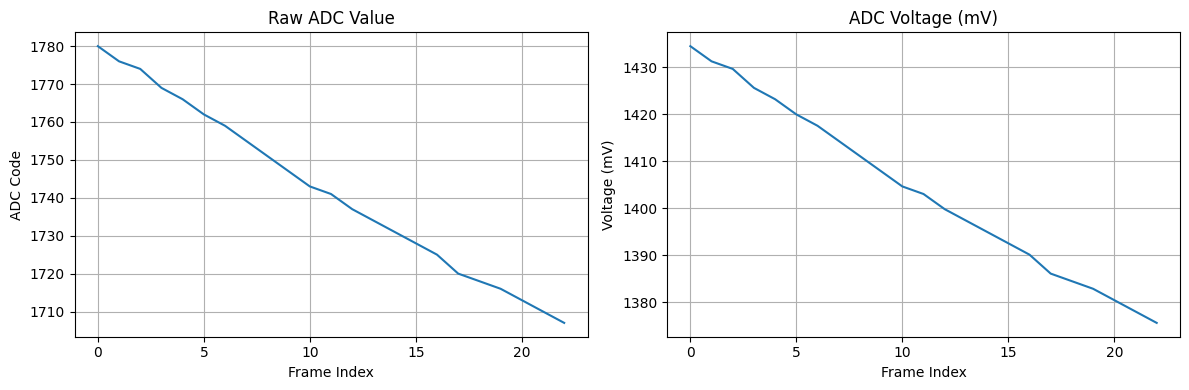

In [153]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 参数配置
# -----------------------------
ADC_FILE = r"capture_20260129_113142\adc.npy"
VREF = 3.3            # 参考电压 3.3V
ADC_BITS = 12         # ADC 位宽
ADC_MAX = (1 << ADC_BITS) - 1

# -----------------------------
# 加载 ADC 数据
# -----------------------------
adc = np.load(ADC_FILE)
x = np.arange(adc.size)

# -----------------------------
# ADC -> mV
# -----------------------------
adc_mv = adc.astype(np.float64) * VREF * 1000.0 / ADC_MAX

# -----------------------------
# 并排显示
# -----------------------------
plt.figure(figsize=(12, 4))

# 左：原始 ADC
plt.subplot(1, 2, 1)
plt.plot(x, adc)
plt.xlabel("Frame Index")
plt.ylabel("ADC Code")
plt.title("Raw ADC Value")
plt.grid(True)

# 右：mV
plt.subplot(1, 2, 2)
plt.plot(x, adc_mv)
plt.xlabel("Frame Index")
plt.ylabel("Voltage (mV)")
plt.title("ADC Voltage (mV)")
plt.grid(True)

plt.tight_layout()
plt.show()


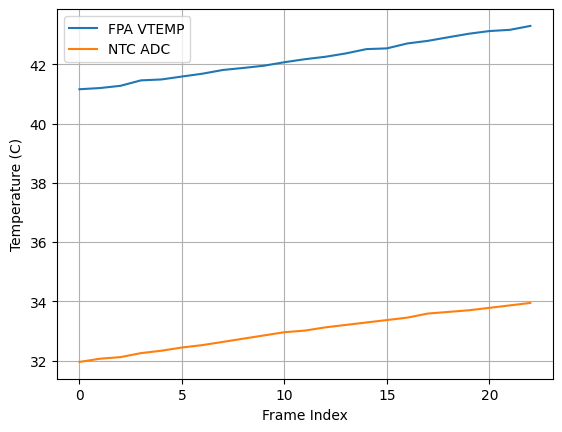

In [154]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import numpy as np
import matplotlib.pyplot as plt

# =============================
# 输入文件路径
# =============================
black_file   = "capture_20260129_113142/black_img.npy"
shutter_file = "capture_20260129_113142/shutter_img.npy"
adc_file     = "capture_20260129_113142/adc.npy"

black = np.load(black_file)      # (N, 120, 162), u16
shutter = np.load(shutter_file)  # (N, 120, 162), u16
adc = np.load(adc_file)          # (N,), u16

assert black.shape == shutter.shape
assert black.shape[0] == adc.shape[0]

num_frames, height, width = black.shape
assert width >= 2

# =============================
# VTEMP -> FPA 温度
# =============================
# 每行最后两个像素是 VTEMP
vtemp_black = black[:, :, -2:].astype(np.float64)
vtemp_shutter = shutter[:, :, -2:].astype(np.float64)

# 同一帧：black + shutter 的所有 VTEMP 一起平均
vtemp_mean = np.mean(
    np.concatenate([vtemp_black, vtemp_shutter], axis=1),
    axis=(1, 2)
)

# T(FPA) = 25 + (VTEMP - 8192) / 70
temp_fpa_c = 25.0 + (vtemp_mean - 8192.0) / 70.0

# =============================
# ADC -> NTC -> 温度
# =============================
RUP = 10_000.0
R0  = 10_000.0
T0  = 298.15
B   = 3435.0

def adc_to_rntc(adc):
    adc = float(adc)
    if adc <= 0 or adc >= 4095:
        return np.nan
    return RUP * adc / (4095.0 - adc)

def rntc_to_temp_c(r):
    if r <= 0 or np.isnan(r):
        return np.nan
    inv_T = 1.0 / T0 + np.log(r / R0) / B
    return 1.0 / inv_T - 273.15

def adc_to_temp_c(adc):
    return rntc_to_temp_c(adc_to_rntc(adc))

temp_adc_c = np.array([adc_to_temp_c(v) for v in adc])

# =============================
# 画图
# =============================
x = np.arange(num_frames)

plt.figure()
plt.plot(x, temp_fpa_c, label="FPA VTEMP")
plt.plot(x, temp_adc_c, label="NTC ADC")
plt.xlabel("Frame Index")
plt.ylabel("Temperature (C)")
plt.legend()
plt.grid(True)
plt.show()
